remove year built/
remove price per sqdt/
remove floor no > total no of floors/
remove grad boost/
test ridge/lasso for different alpha values/
skewness and distributions in eda/
log transform (fix the performance of linear models)

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
warnings.filterwarnings('ignore')

df = pd.read_csv(r'C:\Users\vsmk3\ds_first_git\india_housing_prices.csv')
df = df.drop_duplicates()
print("Shape:", df.shape)
df.head()

Shape: (250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.500000,72168.927986,1.0,62500.75,125000.50,187500.25,250000.00
BHK,250000.0,2.999396,1.415521,1.0,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.0,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.0,254.586854,141.349921,10.0,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.0,0.130597,0.130747,0.0,0.05,0.09,0.16,0.99
Year_Built,250000.0,2006.520012,9.808575,1990.0,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.0,14.966800,8.948047,0.0,7.00,15.00,23.00,30.00
Total_Floors,250000.0,15.503004,8.671618,1.0,8.00,15.00,23.00,30.00
Age_of_Property,250000.0,18.479988,9.808575,2.0,10.00,18.00,27.00,35.00
Nearby_Schools,250000.0,5.499860,2.878639,1.0,3.00,5.00,8.00,10.00


In [20]:
pd.set_option('display.max_colwidth', None)
# Generate categorical and string column summary
desc = df.describe(include=['O'])

# Append a row containing the list of unique entries for each column
desc.loc['unique_entries'] = df[desc.columns].apply(lambda col: col.dropna().unique().tolist())

desc.T

,count,unique,top,freq,unique_entries
State,250000,20,Odisha,12681,"[Tamil Nadu, Maharashtra, Punjab, Rajasthan, West Bengal, Chhattisgarh, Delhi, Jharkhand, Telangana, Karnataka, Uttar Pradesh, Assam, Uttarakhand, Bihar, Gujarat, Haryana, Andhra Pradesh, Madhya Pradesh, Kerala, Odisha]"
City,250000,42,Coimbatore,6461,"[Chennai, Pune, Ludhiana, Jodhpur, Jaipur, Durgapur, Coimbatore, Bilaspur, New Delhi, Ranchi, Warangal, Bangalore, Nagpur, Lucknow, Silchar, Dehradun, Noida, Gaya, Jamshedpur, Ahmedabad, Hyderabad, Faridabad, Amritsar, Kolkata, Dwarka, Vishakhapatnam, Bhopal, Indore, Haridwar, Mysore, Patna, Raipur, Vijayawada, Trivandrum, Kochi, Surat, Gurgaon, Mangalore, Cuttack, Bhubaneswar, Guwahati, Mumbai]"
Locality,250000,500,Locality_296,567,"[Locality_84, Locality_490, Locality_167, Locality_393, Locality_466, Locality_246, Locality_254, Locality_232, Locality_122, Locality_75, Locality_462, Locality_227, Locality_287, Locality_148, Locality_369, Locality_265, Locality_50, Locality_385, Locality_241, Locality_286, Locality_74, Locality_459, Locality_355, Locality_151, Locality_159, Locality_382, Locality_143, Locality_454, Locality_262, Locality_136, Locality_223, Locality_368, Locality_480, Locality_485, Locality_398, Locality_305, Locality_114, Locality_202, Locality_96, Locality_295, Locality_58, Locality_484, Locality_323, Locality_432, Locality_273, Locality_458, Locality_150, Locality_238, Locality_494, Locality_464, Locality_431, Locality_125, Locality_218, Locality_112, Locality_27, Locality_40, Locality_457, Locality_64, Locality_372, Locality_76, Locality_412, Locality_169, Locality_479, Locality_121, Locality_128, Locality_145, Locality_205, Locality_353, Locality_387, Locality_278, Locality_258, Locality_418, Locality_436, Locality_92, Locality_39, Locality_473, Locality_63, Locality_12, Locality_498, Locality_356, Locality_314, Locality_1, Locality_394, Locality_187, Locality_420, Locality_181, Locality_179, Locality_180, Locality_326, Locality_384, Locality_430, Locality_363, Locality_83, Locality_435, Locality_442, Locality_397, Locality_211, Locality_53, Locality_172, Locality_132, ...]"
Property_Type,250000,3,Villa,83744,"[Apartment, Independent House, Villa]"
Furnished_Status,250000,3,Unfurnished,83408,"[Furnished, Unfurnished, Semi-furnished]"
Public_Transport_Accessibility,250000,3,High,83705,"[High, Low, Medium]"
Parking_Space,250000,2,No,125456,"[No, Yes]"
Security,250000,2,Yes,125233,"[No, Yes]"
Amenities,250000,325,Pool,10218,"[Playground, Gym, Garden, Pool, Clubhouse, Playground, Clubhouse, Pool, Gym, Garden, Clubhouse, Pool, Playground, Gym, Playground, Clubhouse, Gym, Pool, Garden, Playground, Garden, Gym, Pool, Clubhouse, Playground, Clubhouse, Clubhouse, Garden, Playground, Gym, Pool, Clubhouse, Playground, Garden, Clubhouse, Playground, Clubhouse, Playground, Garden, Gym, Clubhouse, Clubhouse, Gym, Playground, Pool, Clubhouse, Garden, Gym, Playground, Pool, Garden, Gym, Playground, Playground, Pool, Playground, Garden, Gym, Pool, Clubhouse, Gym, Garden, Clubhouse, Pool, Gym, Playground, Pool, Playground, Clubhouse, Clubhouse, Gym, Garden, Pool, Playground, Pool, Clubhouse, Gym, Playground, Garden, Garden, Pool, Gym, Playground, Clubhouse, Pool, Gym, Clubhouse, Clubhouse, Garden, Pool, Garden, Playground, Gym, Garden, Playground, Pool, Clubhouse, Pool, Garden, Playground, Pool, Playground, Garden, Pool, Clubhouse, Garden, Clubhouse, Gym, Pool, Clubhouse, Garden, Garden, Pool, Garden, Gym, Garden, Pool, Clubhouse, Playground, Playground, Clubhouse, Garden, Pool, Pool, Gym, Pool, Garden, Playground, Playground, Pool, Gym, Garden, Clubhouse, Playground, Playground, Garden, Garden, Playground, Pool, Playground, Clubhouse, Pool, Garden, Gym, Playground, Clubhouse, Gym, Pool, Playground, Garden, Gym, Clubhouse, Garden, Playground, Pool, Garden, Playground, Clubhouse, Gym, Clubhouse, Gym, Playground, Gym, Pool, Pool, Clubhouse, Clubhouse, Playground, Gym, Pool, Garden, Gym, Clubhouse, Playground, P

Using 11 numeric columns for heatmap
Columns: ['ID', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals']


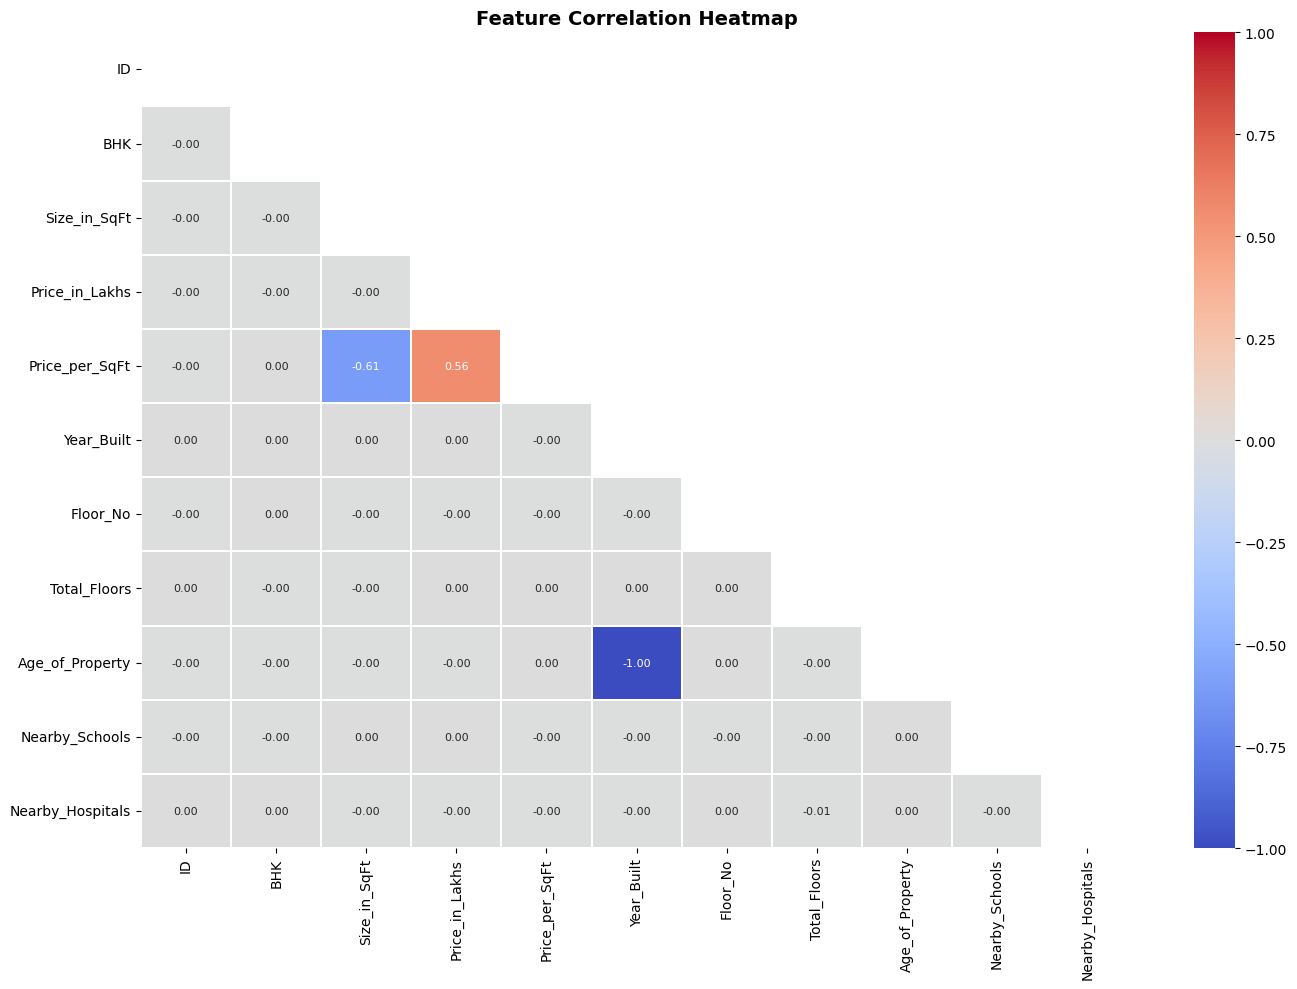

In [21]:
# ── Graph 5: Correlation Heatmap ─────────────────────────────


# Drop datetime/string columns before correlation
df_numeric = df.select_dtypes(include=['float64', 'int64', 'int32', 'float32'])

print(f"Using {df_numeric.shape[1]} numeric columns for heatmap")
print("Columns:", df_numeric.columns.tolist())

plt.figure(figsize=(14, 10))
corr = df_numeric.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,          # shows values inside boxes
    fmt='.2f',           # 2 decimal places
    cmap='coolwarm',
    linewidths=0.3,
    vmin=-1, vmax=1,
    annot_kws={"size": 8}
)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('heatmap.png', dpi=150)
plt.show()

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_target_vs_features(df, target, columns):
    # Create a 5x4 grid of subplots
    fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(20, 24))
    
    # Flatten the 2D array of axes into a 1D list for easy iteration
    axes = axes.flatten()
    
    # Iterate through columns and assign each to an axis
    for i, col in enumerate(columns):
        # Stop if we run out of subplot spaces (20 total)
        if i >= 20:
            print("Warning: More than 20 columns provided. Only plotting the first 20.")
            break
            
        sns.scatterplot(data=df, x=col, y=target, alpha=0.4, ax=axes[i])
        
        axes[i].set_title(f'{target} vs {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel(target)
        
    # Remove any empty subplots if you pass fewer than 20 columns
    for j in range(len(columns), len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.show()

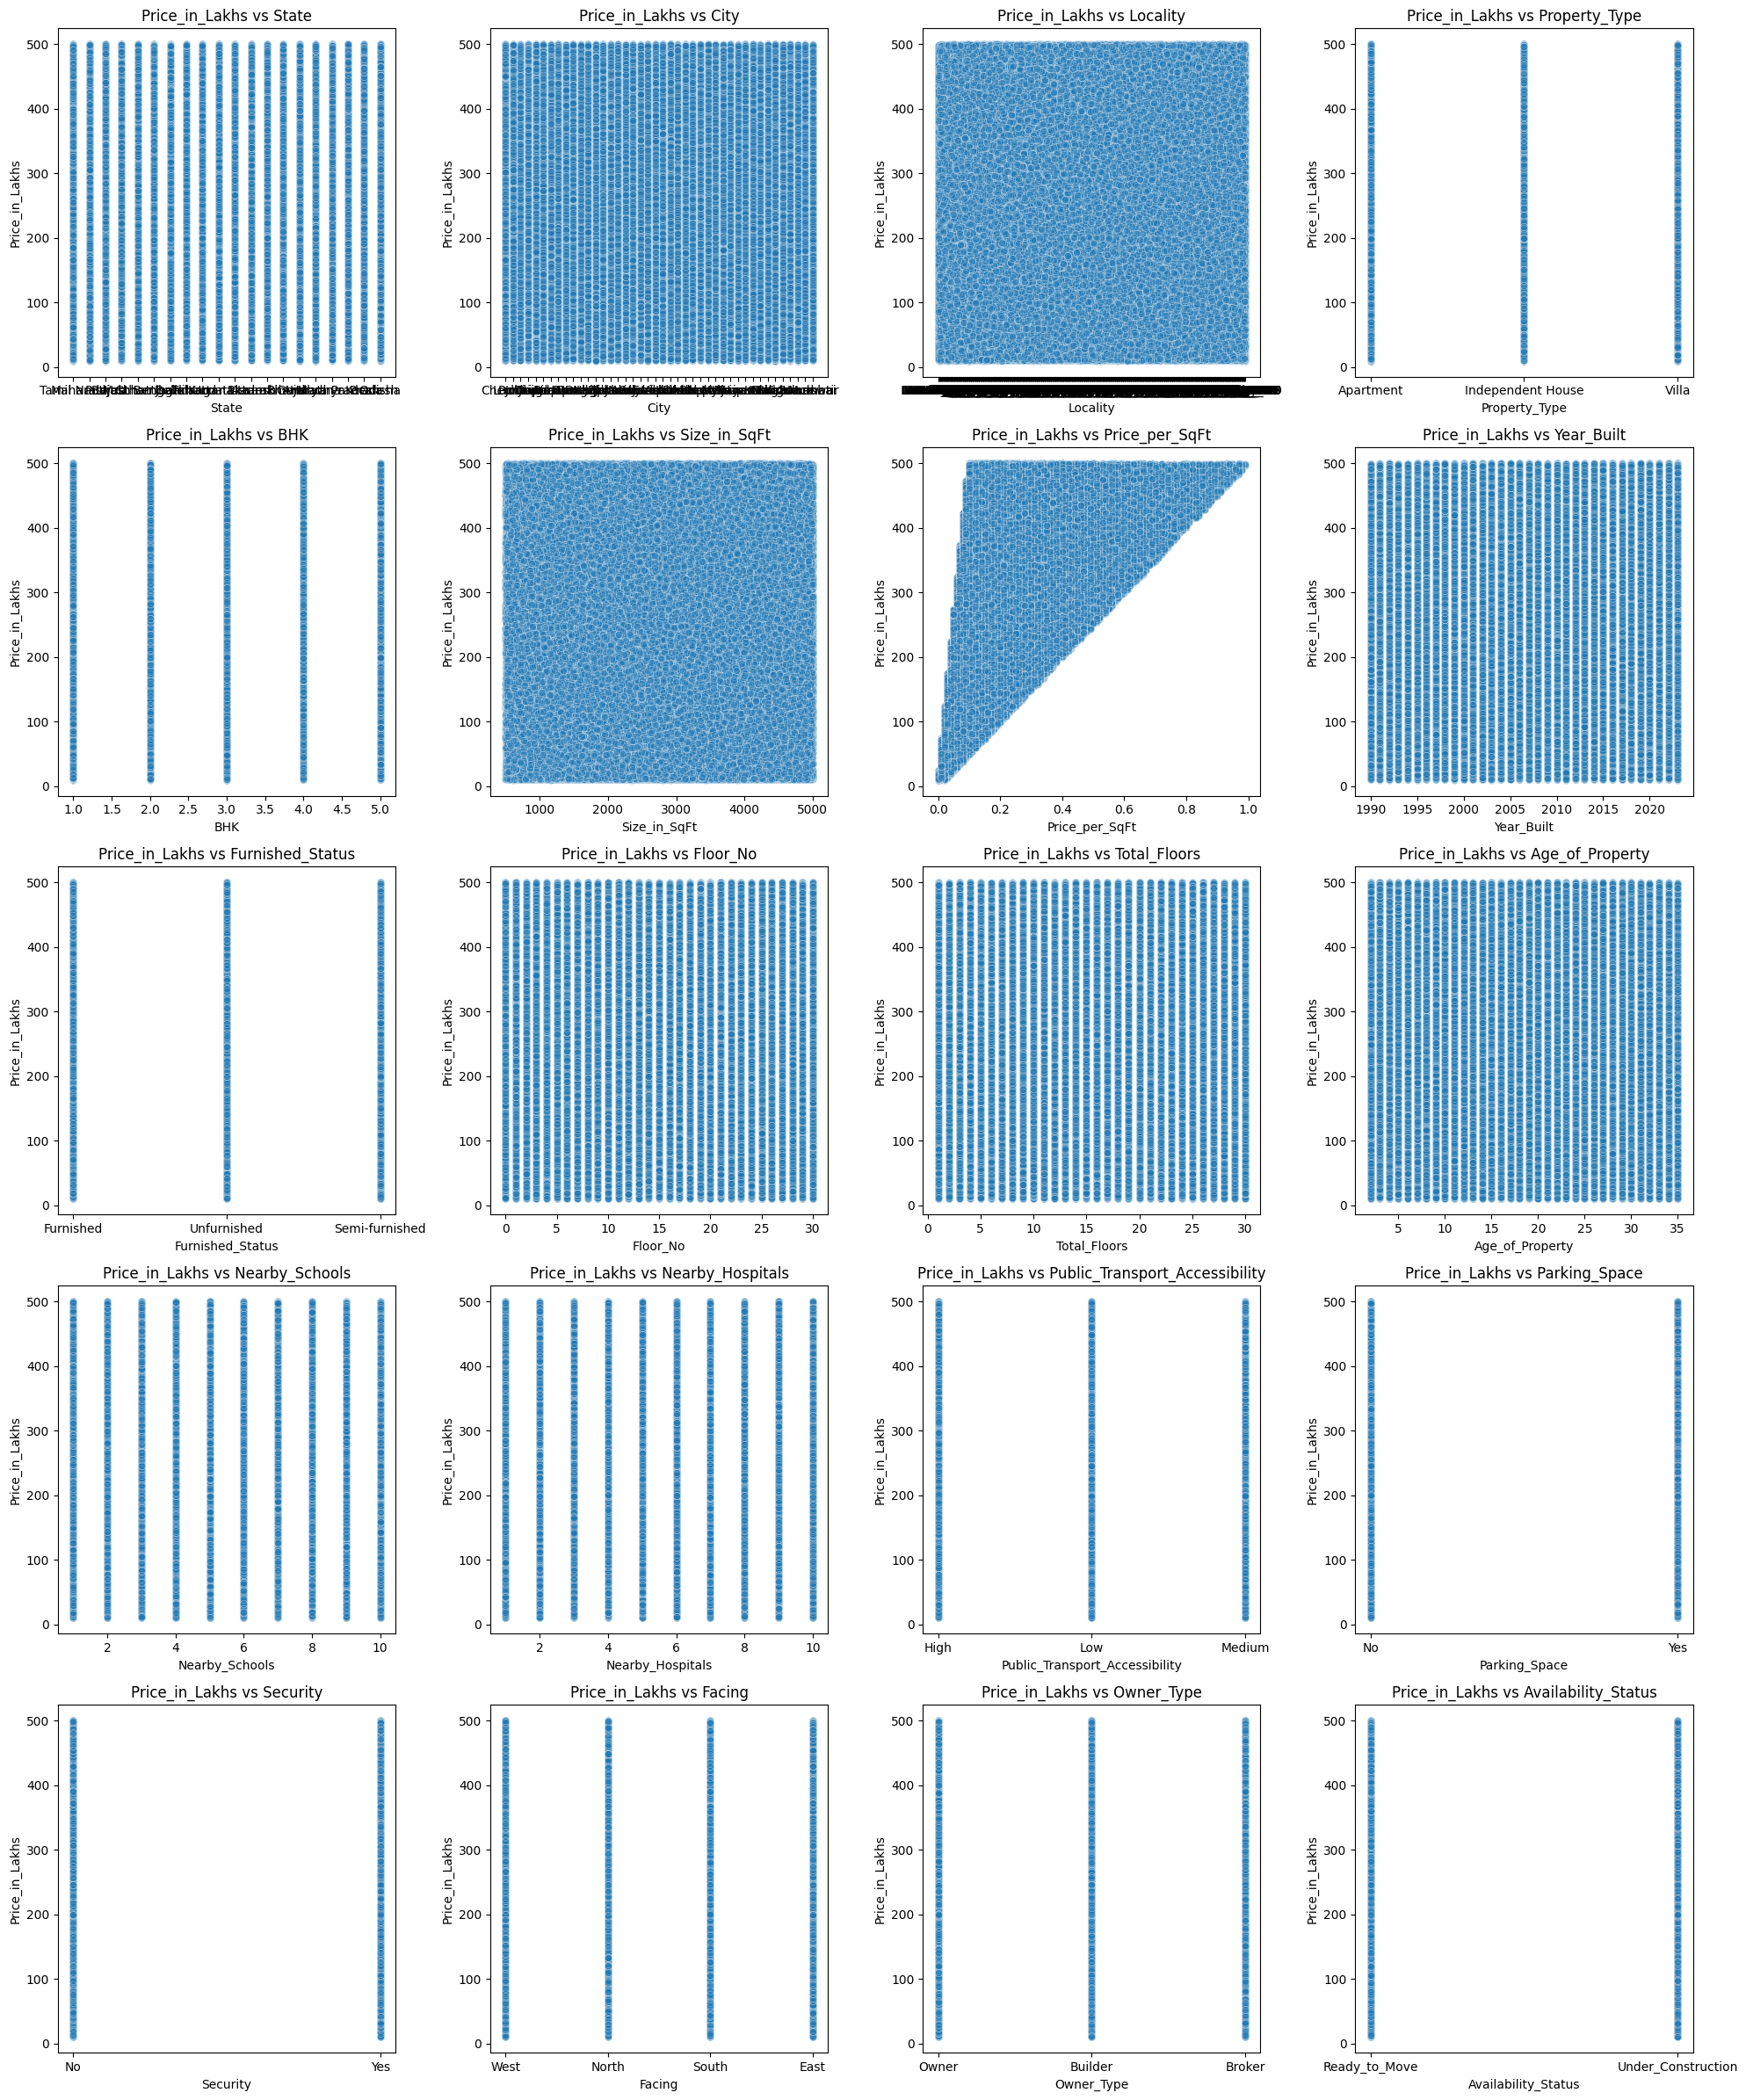

In [23]:
cols = [col for col in df.columns.tolist() if col not in ['Price_in_Lakhs', 'ID', 'Amenities']]
plot_target_vs_features(df, 'Price_in_Lakhs', cols)

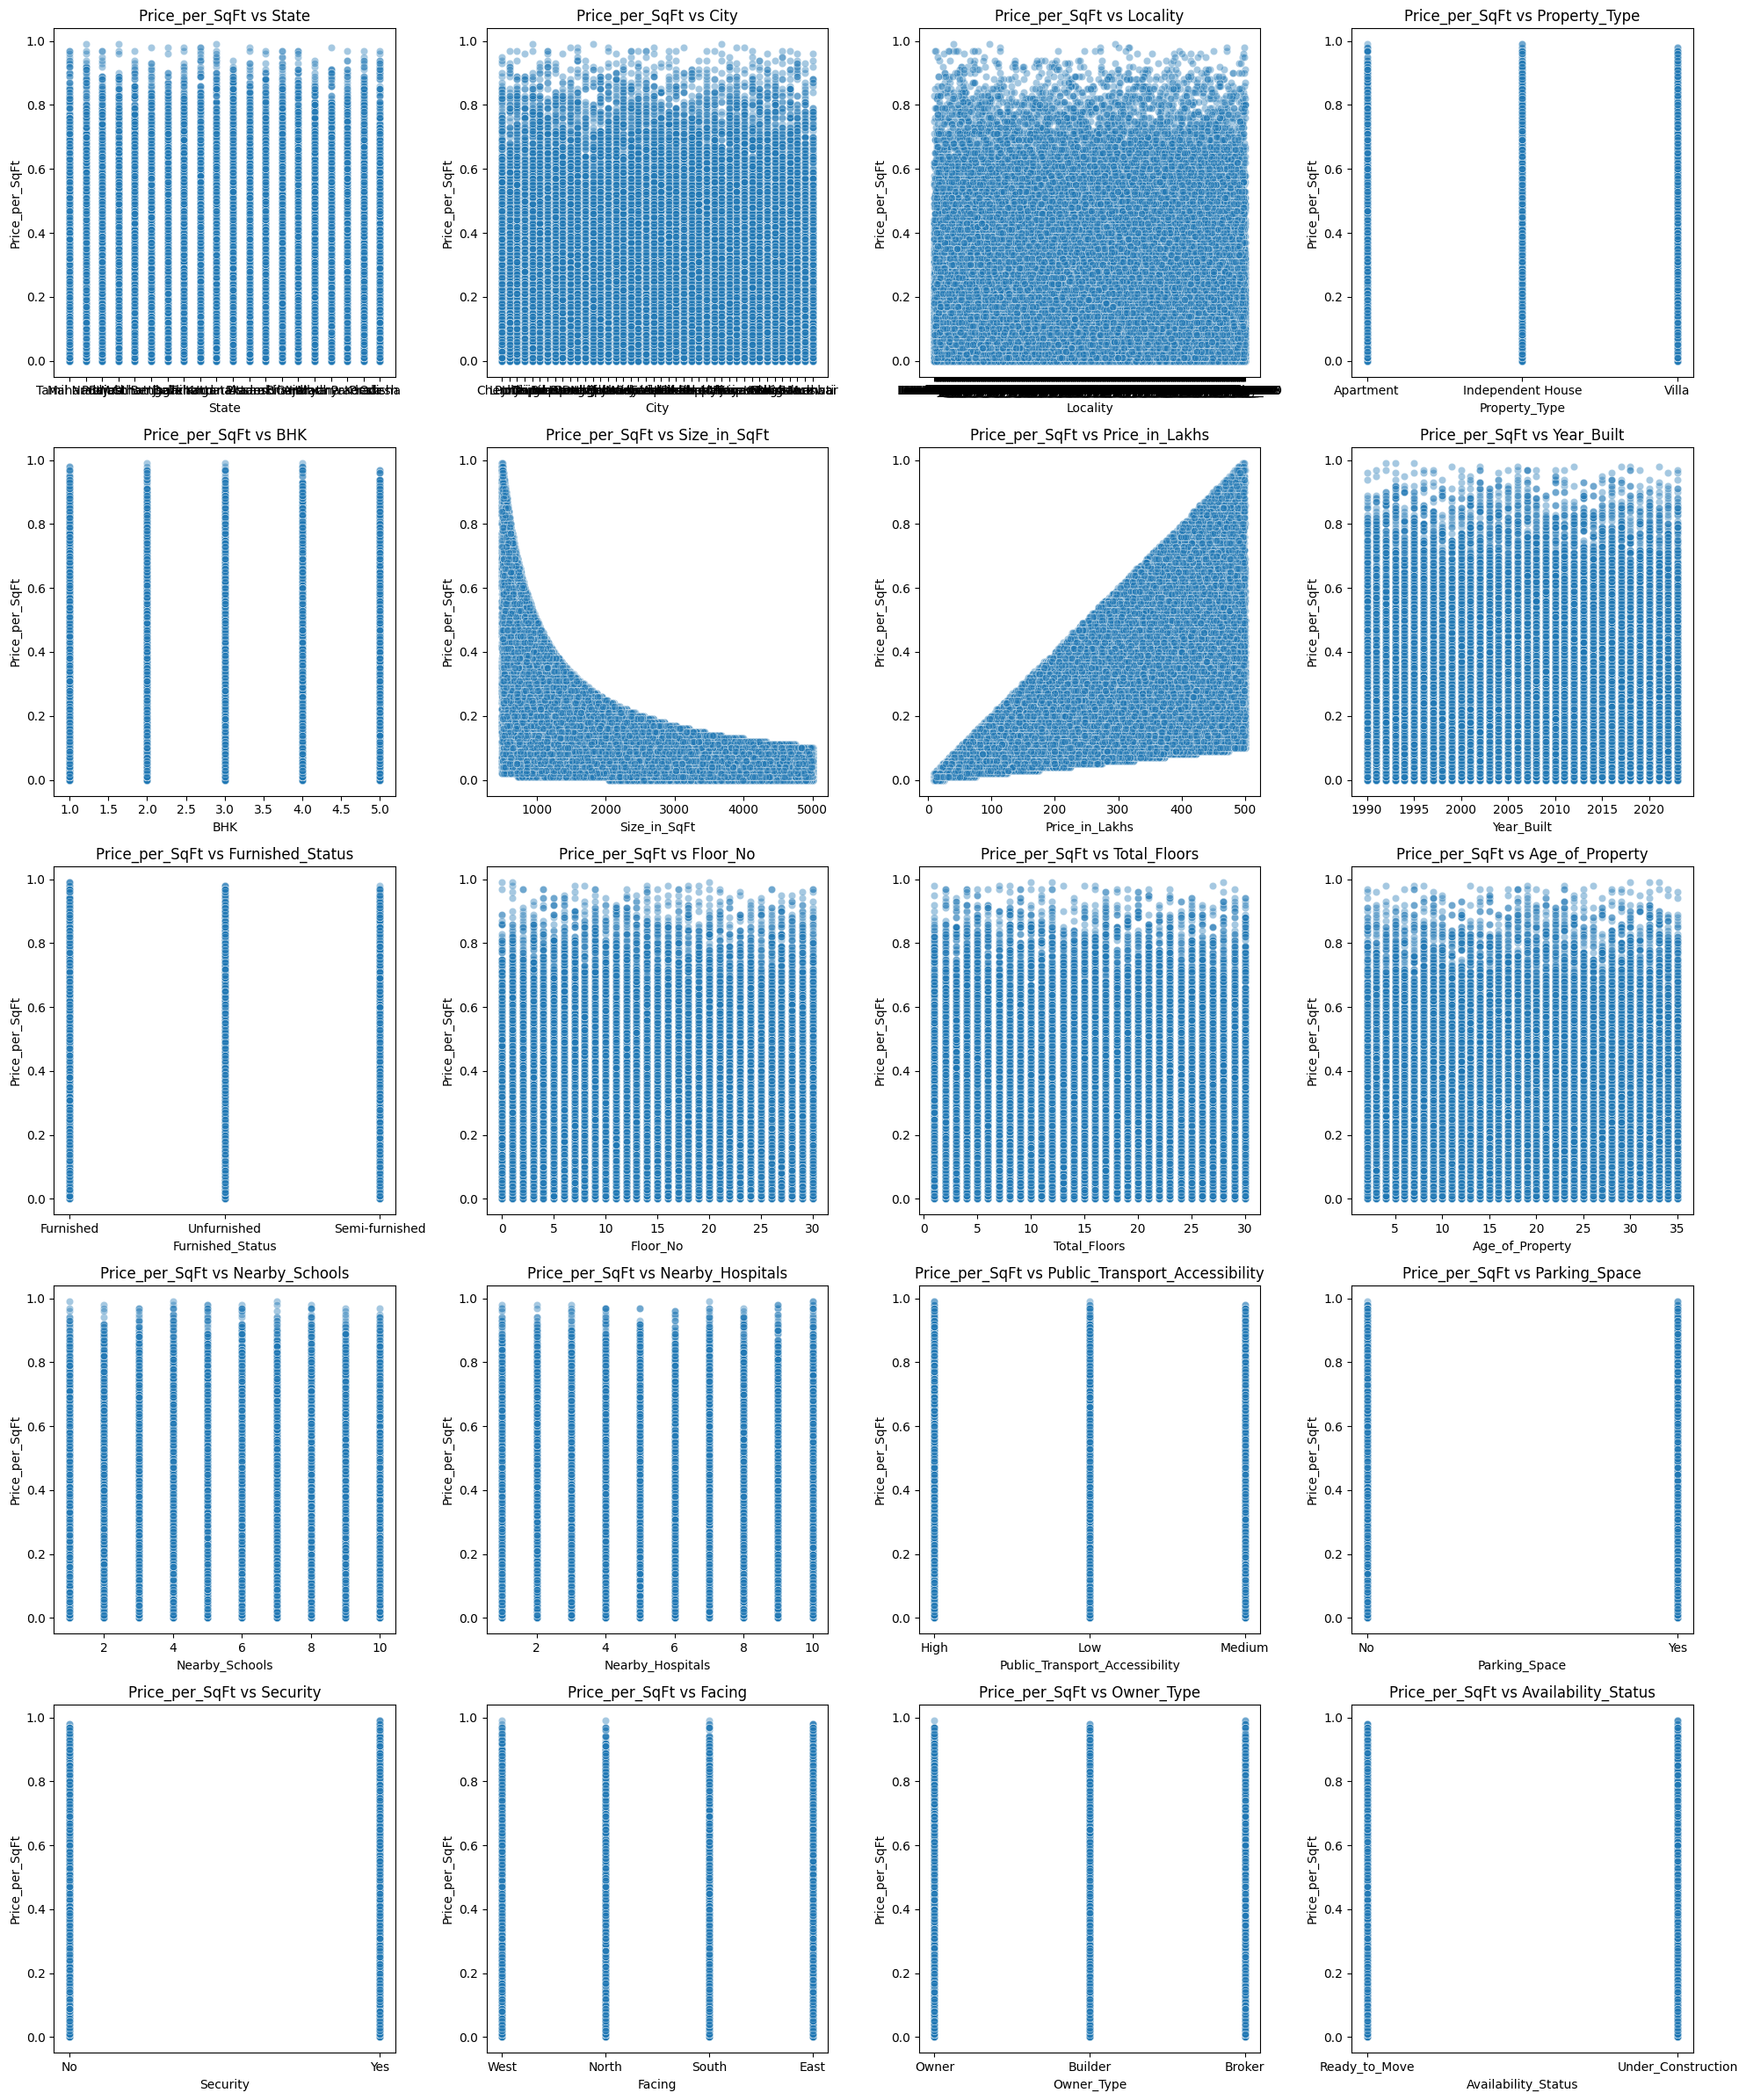

In [24]:
cols = [col for col in df.columns.tolist() if col not in ['Price_per_SqFt', 'ID', 'Amenities']]
plot_target_vs_features(df, 'Price_per_SqFt', cols)

In [25]:
df = df.drop(columns=['Year_Built'])

def remove_invalid_floors(df):
    df = df.copy()
    df = df[df['Floor_No'] <= df['Total_Floors']]
    return df

df = remove_invalid_floors(df)

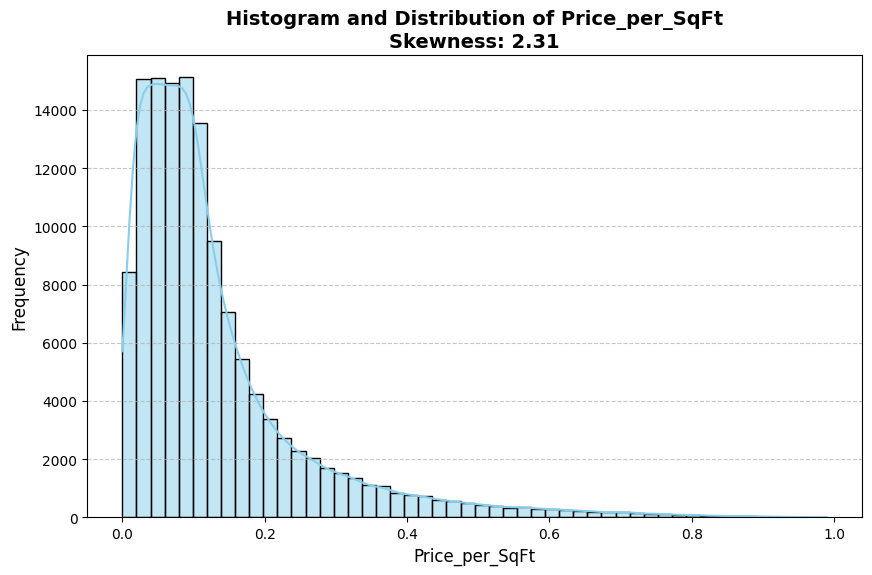

In [26]:
def plot_price_distribution(df, column_name='Price'):
    # Calculate skewness
    skewness = df[column_name].skew()
    
    # Set up the plot figure
    plt.figure(figsize=(10, 6))
    
    # Plot histogram with KDE curve
    sns.histplot(df[column_name].dropna(), kde=True, bins=50, color='skyblue', edgecolor='black')
    
    # Add titles and labels including the calculated skewness
    plt.title(f'Histogram and Distribution of {column_name}\nSkewness: {skewness:.2f}', fontsize=14, fontweight='bold')
    plt.xlabel(column_name, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    
    # Show grid for readability
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.show()
plot_price_distribution(df, 'Price_per_SqFt')

In [27]:
from scipy.stats import skew

# list with only numerical columns
col_numerical = [col for col in df.columns if df[col].dtype != object]

# list with only categorical columns
col_categorical = [col for col in df.columns if col not in col_numerical]
df_copy = df.copy()
skewed = df_copy[col_numerical].apply(lambda x: skew(x.astype(float)))
skewed = skewed[skewed > 0.3]
skewed_df = pd.DataFrame({'skewed':skewed})
skewed_df.skewed.sort_values(ascending=False).head(10)

Price_per_SqFt    2.307368
Floor_No          0.564233
Name: skewed, dtype: float64

In [28]:
# ── Check Missing Values ──────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])

Empty DataFrame
Columns: [Missing Count, Percentage]
Index: []


In [29]:
cat_cols = df.select_dtypes(include=['object']).columns
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
print(len(num_cols), len(cat_cols))

10 12


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Clean column names (good practice)
df.columns = df.columns.str.strip()

# Correct target column
TARGET = 'Price_per_SqFt'

# Features & target
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Handle missing values
X = X.fillna(0)
y = y.fillna(0)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (106956, 21) | Test: (26740, 21)


In [31]:
# ── Remove Outliers using IQR ─────────────────────────────────
train = pd.concat([X_train, y_train], axis=1)
test = pd.concat([X_test, y_test], axis=1)
Q1 = train[num_cols].quantile(0.25)
Q3 = train[num_cols].quantile(0.75)
IQR = Q3 - Q1
train = train[~((train[num_cols] < (Q1 - 1.5 * IQR)) | (train[num_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]
print("Shape after outlier removal:", train.shape)

Shape after outlier removal: (98281, 22)


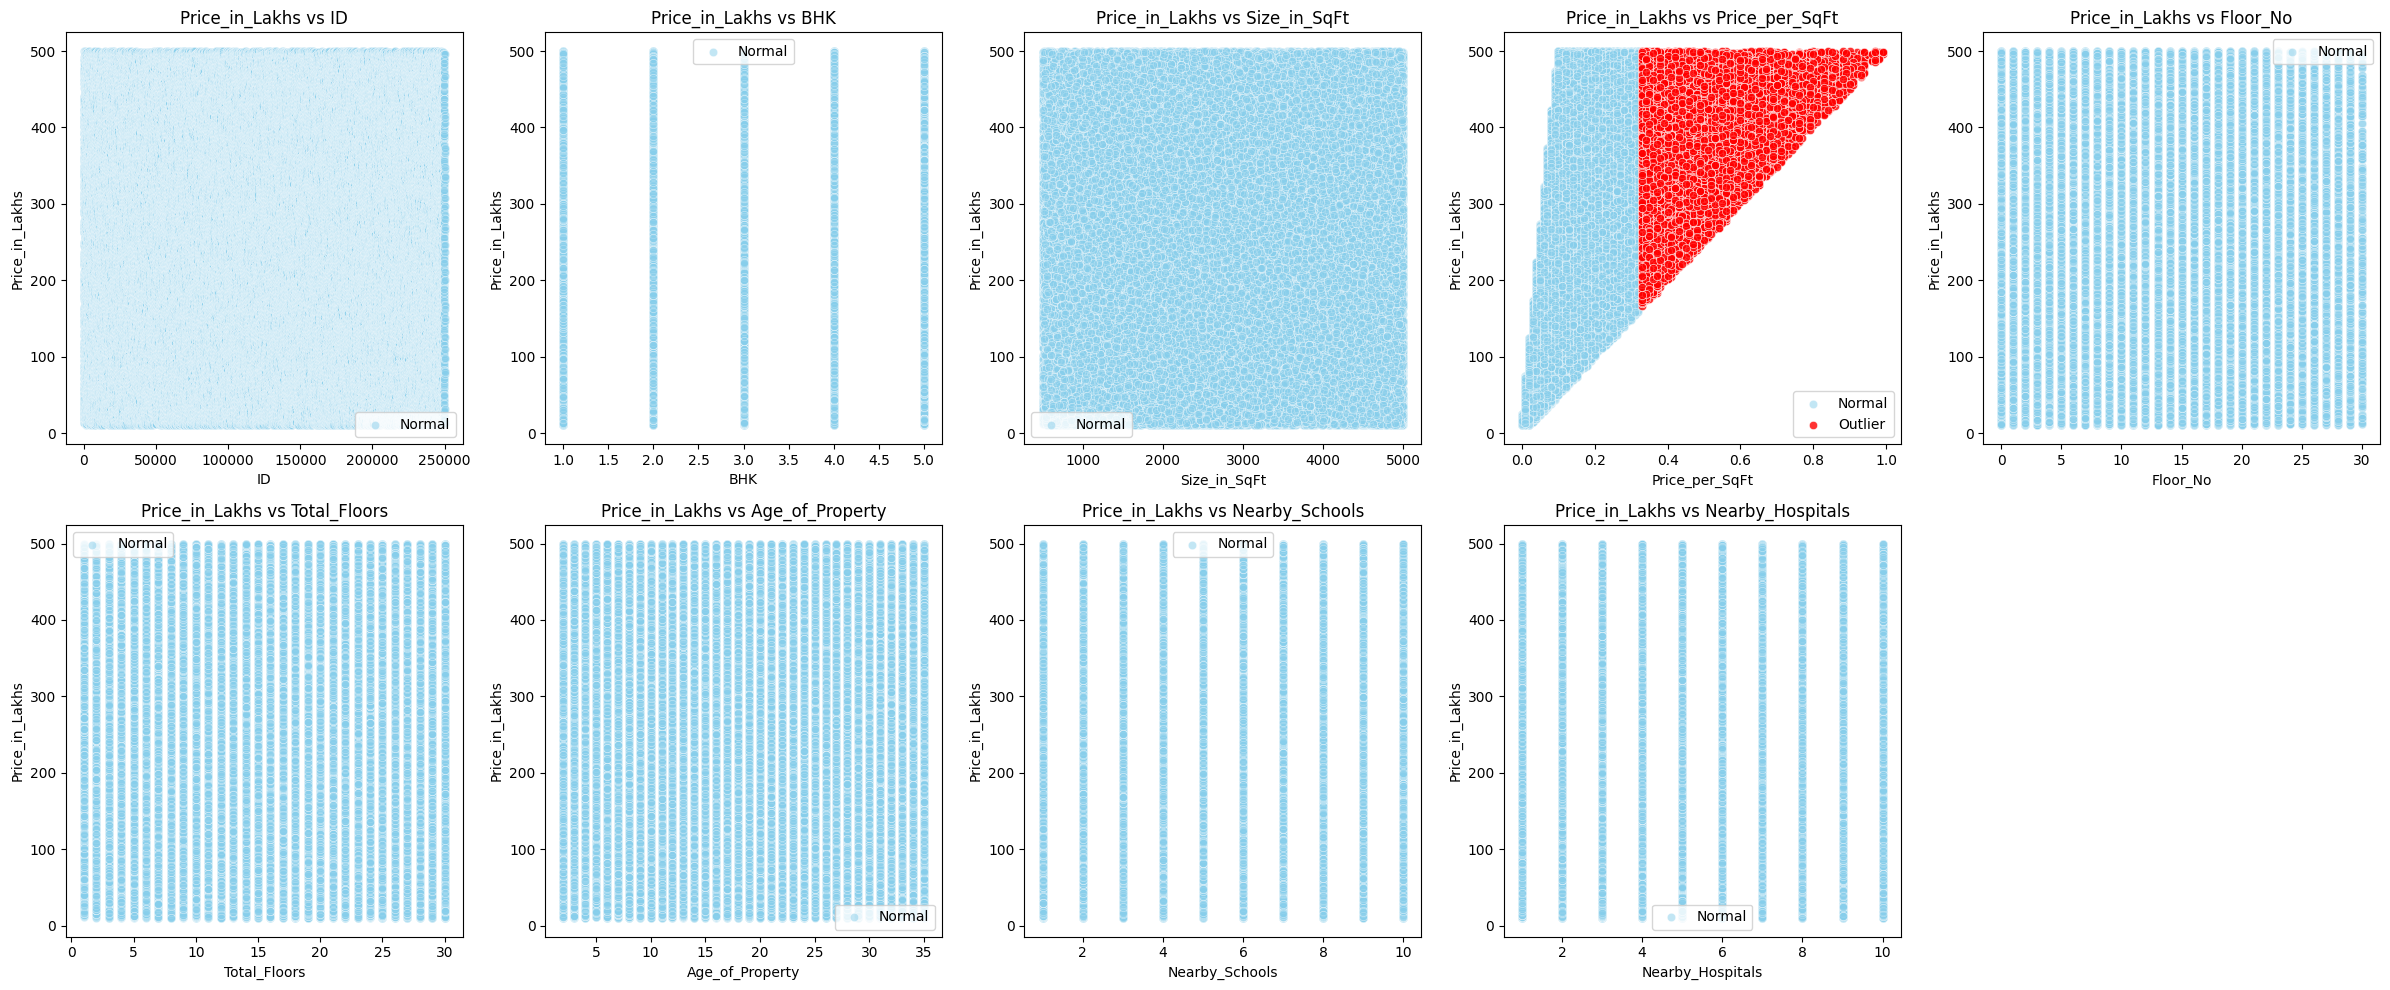

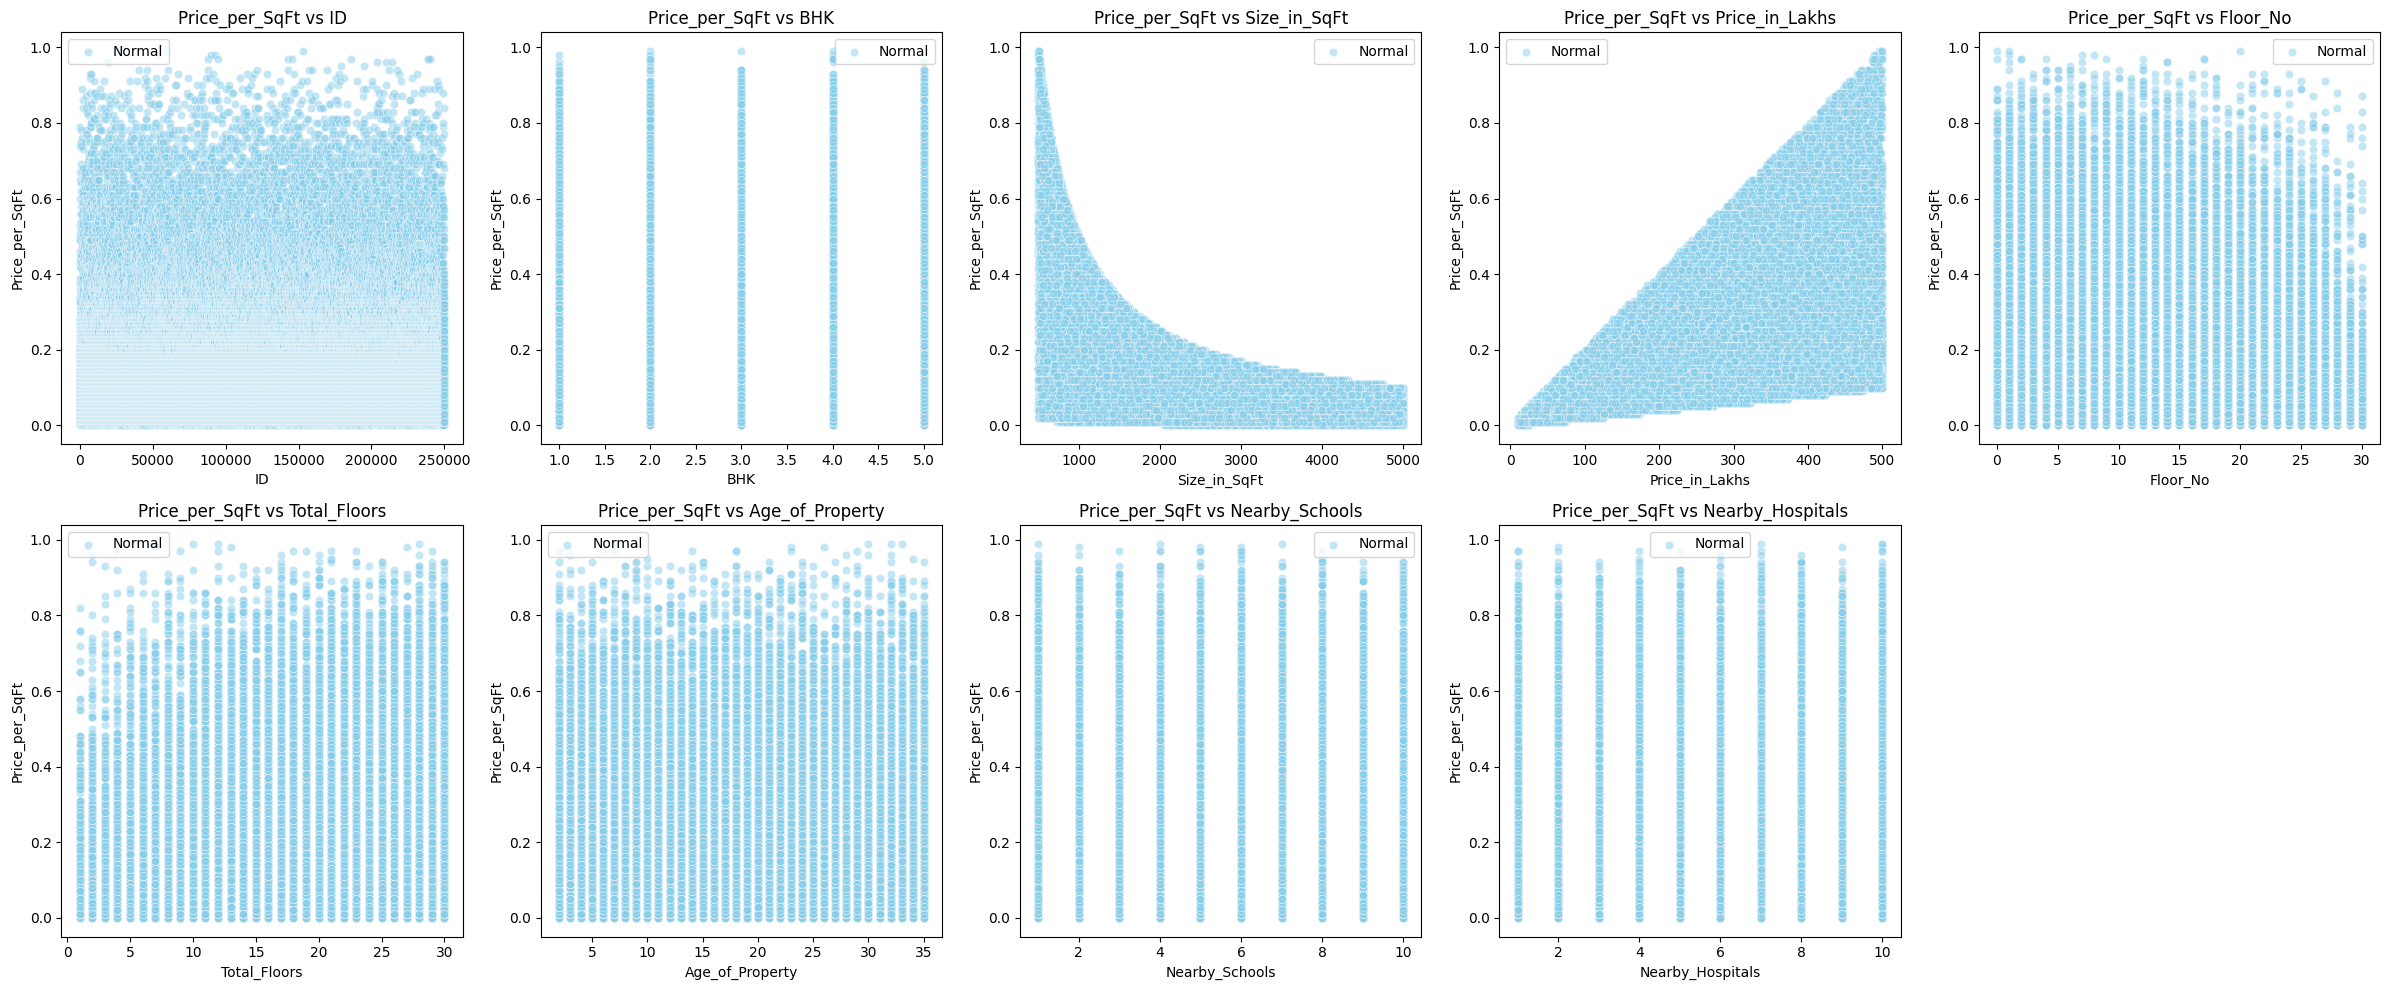

In [32]:
def plot_outliers_2x5(df, num_cols, target_col='Price'):
    # Create a 2x5 grid
    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(24, 10))
    axes = axes.flatten()
    
    # Filter to ensure we only loop through up to 10 columns
    cols_to_plot = [col for col in num_cols if col != target_col][:10]
    
    for i, col in enumerate(cols_to_plot):
        # Calculate IQR for the specific feature
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Identify outliers for this column
        is_outlier = (df[col] < lower_bound) | (df[col] > upper_bound)
        
        # Plot normal points
        sns.scatterplot(
            x=df[~is_outlier][col], 
            y=df[~is_outlier][target_col], 
            ax=axes[i], 
            color='skyblue', 
            alpha=0.5, 
            label='Normal'
        )
        
        # Plot outlier points
        sns.scatterplot(
            x=df[is_outlier][col], 
            y=df[is_outlier][target_col], 
            ax=axes[i], 
            color='red', 
            alpha=0.8, 
            label='Outlier'
        )
        
        axes[i].set_title(f'{target_col} vs {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel(target_col)
    
    # Remove any unused axes if there are fewer than 10 features
    for j in range(len(cols_to_plot), len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.show()

plot_outliers_2x5(df, num_cols, target_col='Price_in_Lakhs')
plot_outliers_2x5(df, num_cols, target_col='Price_per_SqFt')

In [ ]:
def rearrange_amenities(df):
    amenities_dummies = df['Amenities'].str.get_dummies(sep=', ')
    df = pd.concat([df, amenities_dummies], axis=1)
    df = df.drop(columns=['Amenities'])
    return df

train = rearrange_amenities(train)
test = rearrange_amenities(test)
X_train = train.drop(columns=[TARGET])
y_train = train[TARGET]
X_test = test.drop(columns=[TARGET])
y_test = test[TARGET]

print(f'Train: {train.shape} | Test: {test.shape}')


Train: (98281, 26) | Test: (26740, 26)


In [34]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

cat_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns

num_cols = X_train.select_dtypes(
    include='number'
).columns

encoder = OneHotEncoder(
    handle_unknown='ignore',
    drop='first',
    sparse_output=False
)

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', encoder, cat_cols),
        ('num', 'passthrough', num_cols)
    ],
    verbose_feature_names_out=False
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

In [35]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    "Linear Regression":      LinearRegression(),
    "Ridge Regression":       Ridge(alpha=1.0),
    "Lasso Regression":       Lasso(alpha=0.1),
    "Decision Tree":          DecisionTreeRegressor(random_state=42),
    "Random Forest":          RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting":      GradientBoostingRegressor(n_estimators=100, random_state=42),
}

results = []

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train_encoded, y_train)
    y_pred = model.predict(X_test_encoded)

    r2  = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    end = time.perf_counter()
    
    results.append({'Model': name, 'R2 Score': round(r2, 4),
                    'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'Time': round(end - start, 2)})
    print(f"{name:25s} → R²: {r2:.4f} | MAE: {mae:.2f} | RMSE: {rmse:.2f} | Time: {end - start:.2f}s")

results_df = pd.DataFrame(results).sort_values('R2 Score', ascending=False)
print("\n", results_df)

Linear Regression         → R²: 0.5807 | MAE: 0.04 | RMSE: 0.09 | Time: 3.59s
Ridge Regression          → R²: 0.5807 | MAE: 0.04 | RMSE: 0.09 | Time: 0.71s
Lasso Regression          → R²: 0.5780 | MAE: 0.04 | RMSE: 0.09 | Time: 1.18s


KeyboardInterrupt: 

In [ ]:
# ── Graph 1: R2 Score Comparison ──────────────────────────────
plt.figure(figsize=(10, 5))
bars = plt.barh(results_df['Model'], results_df['R2 Score'],
                color=plt.cm.RdYlGn(results_df['R2 Score']))
plt.xlabel('R² Score')
plt.title('Model Comparison — R² Score', fontsize=14, fontweight='bold')
plt.axvline(x=0.8, color='red', linestyle='--', label='Target R²=0.8')
plt.legend()
plt.tight_layout()
plt.savefig('r2_comparison.png')
plt.show()

In [ ]:
# ── Graph 2: Actual vs Predicted (Best Model) ─────────────────
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_best, alpha=0.5, color='steelblue', edgecolors='k', linewidths=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title(f'Actual vs Predicted — {best_model_name}', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted.png')
plt.show()

In [ ]:
# ── Graph 3: Residuals Plot ───────────────────────────────────
residuals = y_test - y_pred_best

plt.figure(figsize=(10, 4))
plt.scatter(y_pred_best, residuals, alpha=0.5, color='coral')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residuals Plot', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('residuals.png')
plt.show()

In [ ]:
# ── Graph 4: Feature Importance (Random Forest) ───────────────
rf_model = models["Random Forest"]
feat_imp = pd.Series(rf_model.feature_importances_, index=df.drop(columns=[TARGET]).columns)
feat_imp = feat_imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='bar', color='teal')
plt.title('Top 15 Feature Importances — Random Forest', fontsize=13, fontweight='bold')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()

In [ ]:
# ── Graph 6: Price Distribution ───────────────────────────────
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
df[TARGET].hist(bins=40, color='steelblue', edgecolor='white')
plt.title('Price Distribution')
plt.xlabel('Price')

plt.subplot(1, 2, 2)
np.log1p(df[TARGET]).hist(bins=40, color='coral', edgecolor='white')
plt.title('Log(Price) Distribution')
plt.xlabel('Log Price')

plt.suptitle('House Price Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('price_dist.png')
plt.show()

In [ ]:
print("=" * 50)
print(f"  🏆 Best Model : {results_df.iloc[0]['Model']}")
print(f"  ✅ R² Score   : {results_df.iloc[0]['R2 Score']}")
print(f"  📉 MAE        : {results_df.iloc[0]['MAE']}")
print(f"  📉 RMSE       : {results_df.iloc[0]['RMSE']}")
print("=" * 50)